# 03. 功能富集

本 notebook 检验 environmental association signals 在位点和基因层级的富集，并实施审稿中要求的条件生物学背景、匹配对照、LD-aware analyses 以及 MAF/LoF sensitivity analyses。


In [1]:
import os
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

data_dir = os.path.join(os.getcwd(), "data")
source_dir = os.path.join(data_dir, "source")
results_dir = os.path.join(data_dir, "results")
run_dir = os.path.join(os.getcwd(), "run")

enrich_dir = os.path.join(results_dir, "enrichment")
os.makedirs(enrich_dir, exist_ok=True)

载入contexts设定

In [2]:
import json
import gzip

datasets = {
    'genome': pd.read_hdf(os.path.join(data_dir, "results", "site_contexts.genome.maf0.05.h5"), key="df"), # All variants with MAF >= 0.05
    'cds': pd.read_hdf(os.path.join(data_dir, "results", "site_contexts.cds.maf0.01.h5"), key="df"), # All variants in coding regions with MAF >= 0.01
    'gene': pd.read_hdf(os.path.join(data_dir, "results", "gene_contexts.h5"), key="df") # All genes
}

datasets['genome']['genome'] = True
datasets['cds']['cds'] = True
datasets['gene']['gene'] = True

contexts_settings_json_file = os.path.join(os.getcwd(), "config", "contexts_settings.json")
with open(contexts_settings_json_file, "r") as f:
    contexts_settings = json.load(f)

载入envGWAS结果

In [3]:
import numpy as np
# genome site level envGWAS results
env_id_list = ["bio18", "gsl", "al", "striga"]
env_metadata_df = pd.read_csv(os.path.join(data_dir, "source", "envir_metadata.csv"))
for env_id in env_id_list:
    env_df = pd.read_hdf(os.path.join(data_dir, "results", "gwas", env_id, f"{env_id}.gemma", f"{env_id}.gemma.gwas_df.h5"), key="df")
    env_df = env_df[['ID', 'P_WALD']]
    env_df = env_df.rename(columns={'P_WALD': env_id})
    env_df[env_id] = -np.log10(env_df[env_id])
    datasets['genome'] = datasets['genome'].merge(env_df, on='ID', how='left')

    env_cds_df = pd.read_hdf(os.path.join(data_dir, "results", "gwas", env_id, f"{env_id}_cds.gemma", f"{env_id}_cds.gemma.gwas_df.h5"), key="df")
    env_cds_df = env_cds_df[['ID', 'P_WALD']]
    env_cds_df = env_cds_df.rename(columns={'P_WALD': env_id})
    env_cds_df[env_id] = -np.log10(env_cds_df[env_id])
    datasets['cds'] = datasets['cds'].merge(env_cds_df, on='ID', how='left')

    env_gene_df = pd.read_hdf(os.path.join(data_dir, "results", "gwas", env_id, f"{env_id}.magma", f"{env_id}.magma.gwas_df.h5"), key="df")
    env_gene_df = env_gene_df[['ID', 'P_VALUE']]
    env_gene_df = env_gene_df.rename(columns={'P_VALUE': env_id})
    env_gene_df[env_id] = -np.log10(env_gene_df[env_id])
    datasets['gene'] = datasets['gene'].merge(env_gene_df, on='ID', how='left')

载入contrasts设定

In [4]:
contrasts_settings_json_file = os.path.join(os.getcwd(), "config", "contrasts_settings.json")
with open(contrasts_settings_json_file, "r") as f:
    contrasts_settings = json.load(f)

## 1. Genomic compartments

### 1.1 genic_2kb_vs_genome

In [11]:
from src.enrich import contrast_runner

contrast_id = "genic_2kb_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: genic_2kb_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: genic_2kb
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast genic_2kb_vs_genome, skipping.


Enrichment results for contrast: genic_2kb_vs_genome


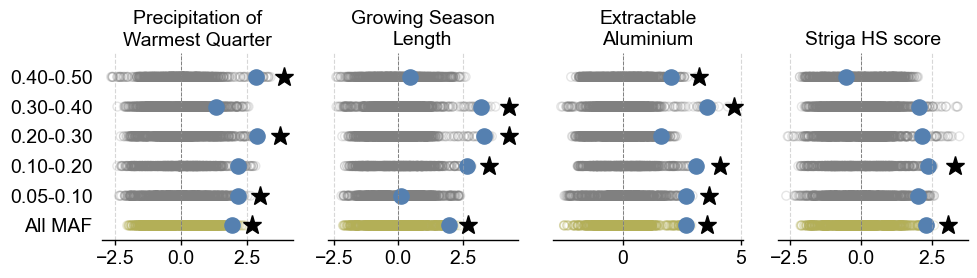

In [12]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

### 1.2 TE_vs_genome

In [13]:
from src.enrich import contrast_runner

contrast_id = "TE_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: TE_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: TE
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 26.2s | 38.13/s | ETA 0.0s
1000 permutations with pool_num=40: 26.37 s (37.93 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.5s | 117.43/s | ETA 0.0s
1000 permutations with pool_num=40: 8.68 s (115.25 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.6s | 104.53/s | ETA 0.0s
1000 permutations with pool_num=40: 9.71 s (102.99 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.3s | 187.48/s | ETA 0.0s
1000 permutations with pool_num=40: 5.48 s (182.56 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.0s | 199.23/s | ETA 0.0s
1000 permutations with pool_num=40: 5.14 s (194.42 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 

Enrichment results for contrast: TE_vs_genome


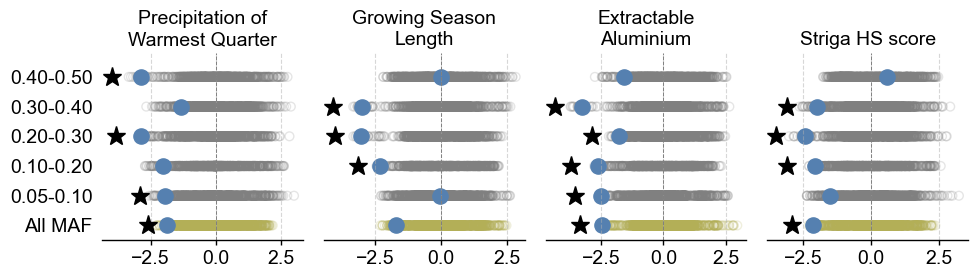

In [14]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

### 1.3 other_intergenic_vs_genome

In [15]:
from src.enrich import contrast_runner

contrast_id = "other_intergenic_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: other_intergenic_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: other_intergenic
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 28.1s | 35.63/s | ETA 0.0s
1000 permutations with pool_num=40: 28.32 s (35.31 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.6s | 116.04/s | ETA 0.0s
1000 permutations with pool_num=40: 8.76 s (114.14 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.2s | 109.12/s | ETA 0.0s
1000 permutations with pool_num=40: 9.31 s (107.40 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.2s | 192.56/s | ETA 0.0s
1000 permutations with pool_num=40: 5.31 s (188.42 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.5s | 222.40/s | ETA 0.0s
1000 permutations with pool_num=40: 4.62 s (216.64 permutations/s)
Permutations: 1

Enrichment results for contrast: other_intergenic_vs_genome


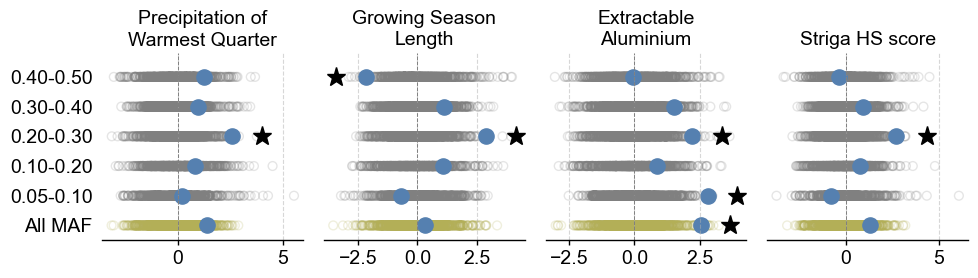

In [16]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

## 2. Gene Structure

### 2.1 在基因区内部比较

#### 2.1.1 upstream_2kb_vs_genic

In [19]:
from src.enrich import contrast_runner

contrast_id = "upstream_2kb_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: upstream_2kb_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: upstream_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 13.6s | 73.58/s | ETA 0.0s
1000 permutations with pool_num=40: 13.82 s (72.35 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.9s | 203.87/s | ETA 0.0s
1000 permutations with pool_num=40: 5.02 s (199.28 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.6s | 215.51/s | ETA 0.0s
1000 permutations with pool_num=40: 4.75 s (210.41 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.4s | 291.88/s | ETA 0.0s
1000 permutations with pool_num=40: 3.55 s (281.97 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.3s | 300.61/s | ETA 0.0s
1000 permutations with pool_num=40: 3.45 s (290.20 permutations/s)
Permutations: 1000/10

Enrichment results for contrast: upstream_2kb_vs_genic


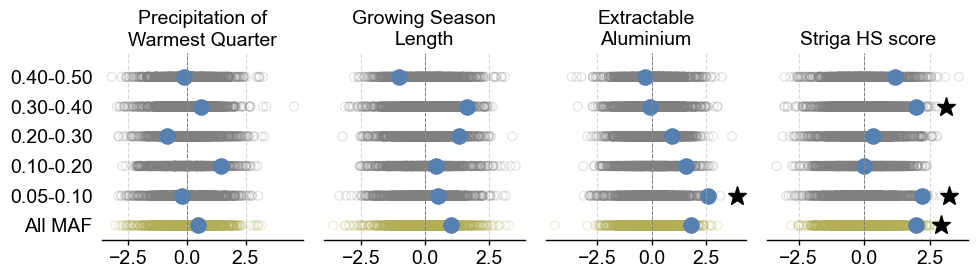

In [20]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.1.2 five_prime_UTR_vs_genic

In [21]:
from src.enrich import contrast_runner

contrast_id = "five_prime_UTR_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: five_prime_UTR_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: five_prime_UTR
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 12.6s | 79.25/s | ETA 0.0s
1000 permutations with pool_num=40: 12.90 s (77.52 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.2s | 192.22/s | ETA 0.0s
1000 permutations with pool_num=40: 5.31 s (188.21 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.4s | 185.10/s | ETA 0.0s
1000 permutations with pool_num=40: 5.51 s (181.44 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.6s | 281.18/s | ETA 0.0s
1000 permutations with pool_num=40: 3.66 s (273.35 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.8s | 263.32/s | ETA 0.0s
1000 permutations with pool_num=40: 3.91 s (255.77 permutations/s)
Permutations: 100

Enrichment results for contrast: five_prime_UTR_vs_genic


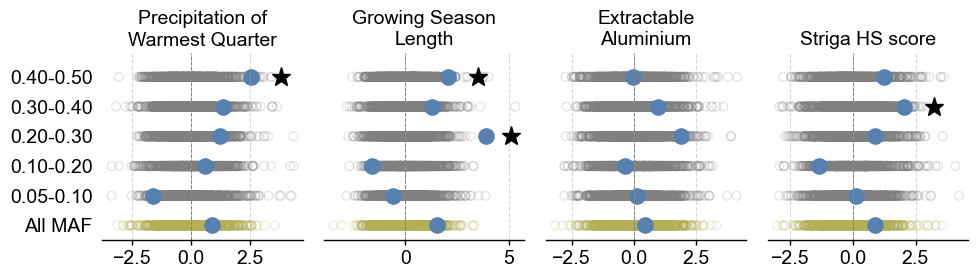

In [22]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.1.3 CDS_vs_genic

In [23]:
from src.enrich import contrast_runner

contrast_id = "CDS_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: CDS_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: CDS
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 13.1s | 76.09/s | ETA 0.0s
1000 permutations with pool_num=40: 13.35 s (74.89 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.9s | 203.39/s | ETA 0.0s
1000 permutations with pool_num=40: 5.05 s (198.13 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.4s | 226.14/s | ETA 0.0s
1000 permutations with pool_num=40: 4.53 s (220.52 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.5s | 282.71/s | ETA 0.0s
1000 permutations with pool_num=40: 3.64 s (274.61 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.2s | 309.93/s | ETA 0.0s
1000 permutations with pool_num=40: 3.33 s (300.43 permutations/s)
Permutations: 1000/1000 (100.0%) | elap

Enrichment results for contrast: CDS_vs_genic


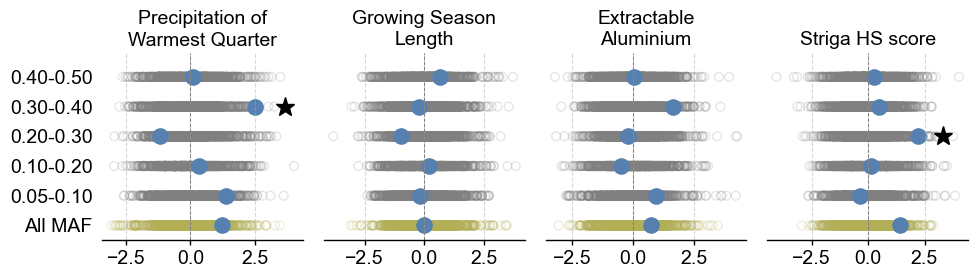

In [24]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.1.4 intron_vs_genic

In [29]:
from src.enrich import contrast_runner

contrast_id = "intron_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: intron_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: intron
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast intron_vs_genic, skipping.


Enrichment results for contrast: intron_vs_genic


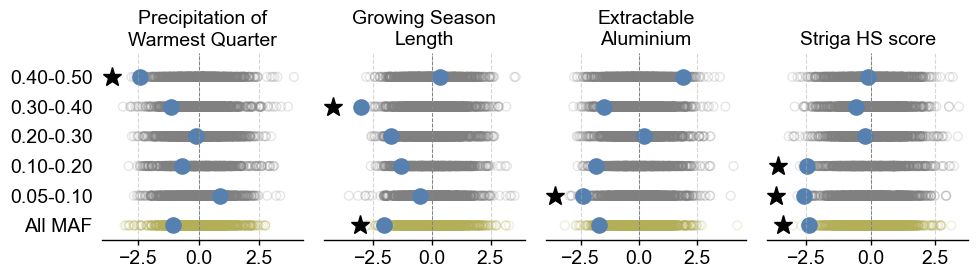

In [30]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.1.5 three_prime_UTR_vs_genic

In [31]:
from src.enrich import contrast_runner

contrast_id = "three_prime_UTR_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: three_prime_UTR_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: three_prime_UTR
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast three_prime_UTR_vs_genic, skipping.


Enrichment results for contrast: three_prime_UTR_vs_genic


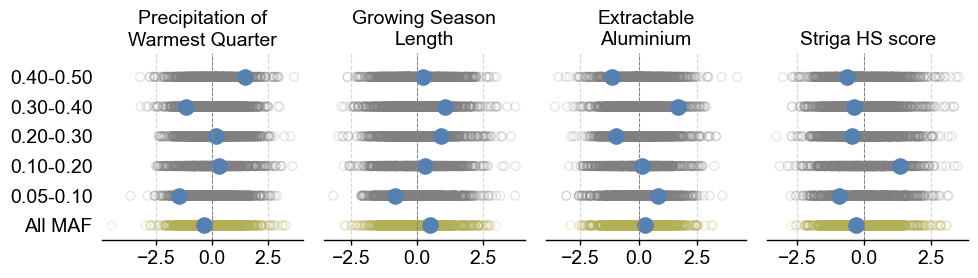

In [32]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.1.6 downstream_2kb_vs_genic

In [33]:
from src.enrich import contrast_runner

contrast_id = "downstream_2kb_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: downstream_2kb_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: downstream_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 12.4s | 80.88/s | ETA 0.0s
1000 permutations with pool_num=40: 12.58 s (79.47 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.4s | 229.56/s | ETA 0.0s
1000 permutations with pool_num=40: 4.49 s (222.90 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.2s | 237.23/s | ETA 0.0s
1000 permutations with pool_num=40: 4.35 s (229.65 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.5s | 285.11/s | ETA 0.0s
1000 permutations with pool_num=40: 3.64 s (274.88 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.2s | 311.78/s | ETA 0.0s
1000 permutations with pool_num=40: 3.33 s (300.38 permutations/s)
Permutations: 100

Enrichment results for contrast: downstream_2kb_vs_genic


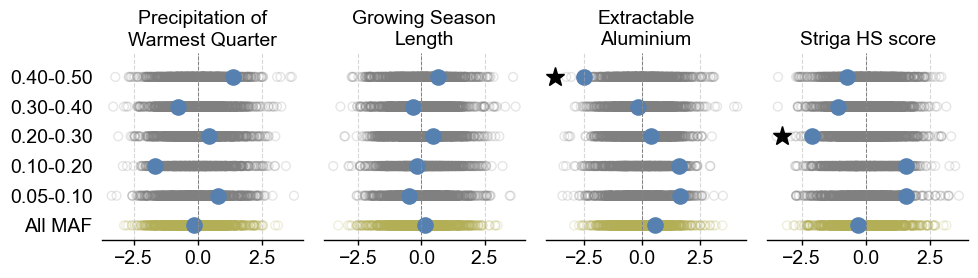

In [35]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

### 2.2 在基因组范围比较

#### 2.2.1 upstream_2kb_vs_genome

In [36]:
from src.enrich import contrast_runner

contrast_id = "upstream_2kb_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: upstream_2kb_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: upstream_2kb
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 26.4s | 37.87/s | ETA 0.0s
1000 permutations with pool_num=40: 26.63 s (37.55 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.4s | 106.66/s | ETA 0.0s
1000 permutations with pool_num=40: 9.52 s (105.04 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.3s | 120.31/s | ETA 0.0s
1000 permutations with pool_num=40: 8.46 s (118.26 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.7s | 176.30/s | ETA 0.0s
1000 permutations with pool_num=40: 5.80 s (172.33 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.9s | 202.50/s | ETA 0.0s
1000 permutations with pool_num=40: 5.06 s (197.56 permutations/s)
Permutations: 1000/1000

Enrichment results for contrast: upstream_2kb_vs_genome


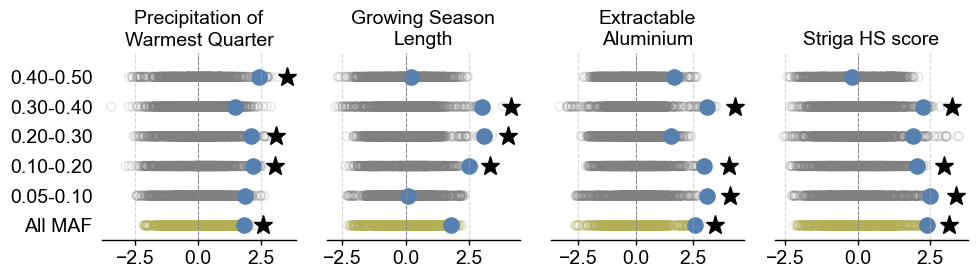

In [37]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.2.2 five_prime_UTR_vs_genome

In [38]:
from src.enrich import contrast_runner

contrast_id = "five_prime_UTR_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: five_prime_UTR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: five_prime_UTR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 27.3s | 36.61/s | ETA 0.0s
1000 permutations with pool_num=40: 27.48 s (36.39 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.3s | 119.77/s | ETA 0.0s
1000 permutations with pool_num=40: 8.50 s (117.60 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.8s | 113.47/s | ETA 0.0s
1000 permutations with pool_num=40: 8.98 s (111.40 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.1s | 197.78/s | ETA 0.0s
1000 permutations with pool_num=40: 5.19 s (192.71 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.2s | 191.97/s | ETA 0.0s
1000 permutations with pool_num=40: 5.36 s (186.71 permutations/s)
Permutations: 1000/

Enrichment results for contrast: five_prime_UTR_vs_genome


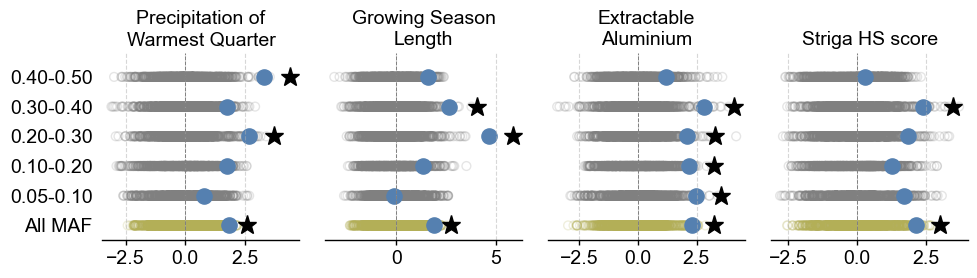

In [39]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.2.3 CDS_vs_genome

In [40]:
from src.enrich import contrast_runner

contrast_id = "CDS_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: CDS_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: CDS
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 27.2s | 36.73/s | ETA 0.0s
1000 permutations with pool_num=40: 27.38 s (36.52 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.1s | 109.57/s | ETA 0.0s
1000 permutations with pool_num=40: 9.25 s (108.08 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.7s | 115.60/s | ETA 0.0s
1000 permutations with pool_num=40: 8.78 s (113.88 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.4s | 185.71/s | ETA 0.0s
1000 permutations with pool_num=40: 5.52 s (181.25 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.1s | 197.51/s | ETA 0.0s
1000 permutations with pool_num=40: 5.18 s (192.98 permutations/s)
Permutations: 1000/1000 (100.0%) | elapse

Enrichment results for contrast: CDS_vs_genome


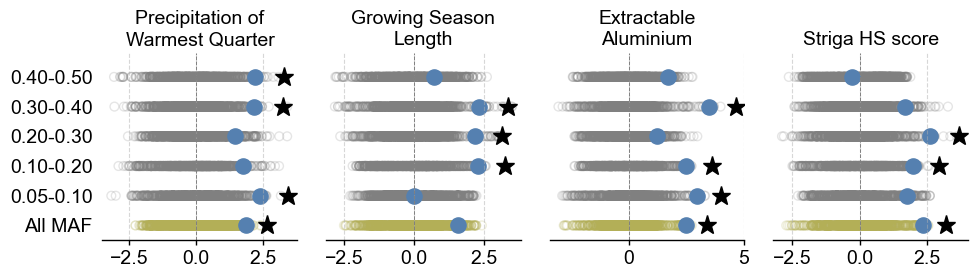

In [41]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.2.4 intron_vs_genome

In [42]:
from src.enrich import contrast_runner

contrast_id = "intron_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: intron_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: intron
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 26.8s | 37.26/s | ETA 0.0s
1000 permutations with pool_num=40: 27.06 s (36.95 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 10.6s | 93.92/s | ETA 0.0s
1000 permutations with pool_num=40: 10.79 s (92.69 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.1s | 109.73/s | ETA 0.0s
1000 permutations with pool_num=40: 9.26 s (108.05 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.5s | 181.09/s | ETA 0.0s
1000 permutations with pool_num=40: 5.63 s (177.48 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.8s | 208.33/s | ETA 0.0s
1000 permutations with pool_num=40: 4.94 s (202.51 permutations/s)
Permutations: 1000/1000 (100.0%) | 

Enrichment results for contrast: intron_vs_genome


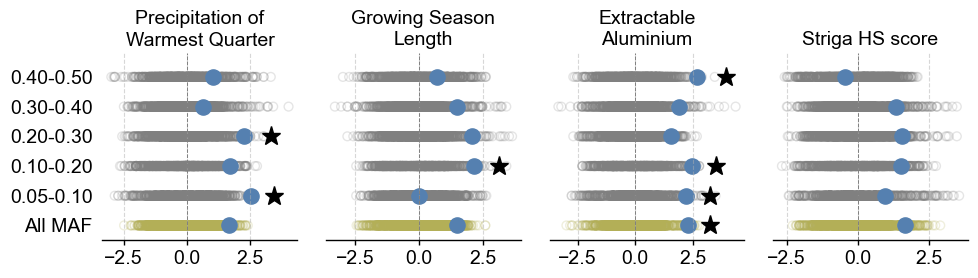

In [43]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.2.5 three_prime_UTR_vs_genome

In [44]:
from src.enrich import contrast_runner

contrast_id = "three_prime_UTR_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: three_prime_UTR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: three_prime_UTR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 27.3s | 36.68/s | ETA 0.0s
1000 permutations with pool_num=40: 27.46 s (36.41 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.1s | 124.07/s | ETA 0.0s
1000 permutations with pool_num=40: 8.18 s (122.24 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.8s | 102.28/s | ETA 0.0s
1000 permutations with pool_num=40: 9.92 s (100.84 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.5s | 183.00/s | ETA 0.0s
1000 permutations with pool_num=40: 5.57 s (179.43 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.6s | 215.68/s | ETA 0.0s
1000 permutations with pool_num=40: 4.77 s (209.56 permutations/s)
Permutations: 100

Enrichment results for contrast: three_prime_UTR_vs_genome


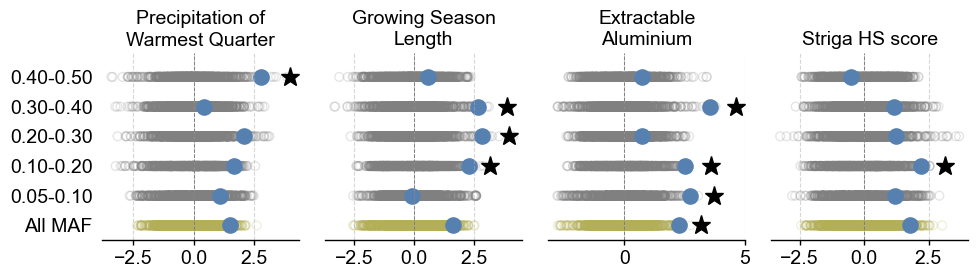

In [45]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.2.6 downstream_2kb_vs_genome

In [46]:
from src.enrich import contrast_runner

contrast_id = "downstream_2kb_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: downstream_2kb_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: downstream_2kb
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 29.2s | 34.23/s | ETA 0.0s
1000 permutations with pool_num=40: 29.45 s (33.96 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.6s | 103.76/s | ETA 0.0s
1000 permutations with pool_num=40: 9.77 s (102.37 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.9s | 112.67/s | ETA 0.0s
1000 permutations with pool_num=40: 9.03 s (110.79 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.5s | 180.54/s | ETA 0.0s
1000 permutations with pool_num=40: 5.69 s (175.86 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.0s | 199.95/s | ETA 0.0s
1000 permutations with pool_num=40: 5.13 s (194.94 permutations/s)
Permutations: 1000/

Enrichment results for contrast: downstream_2kb_vs_genome


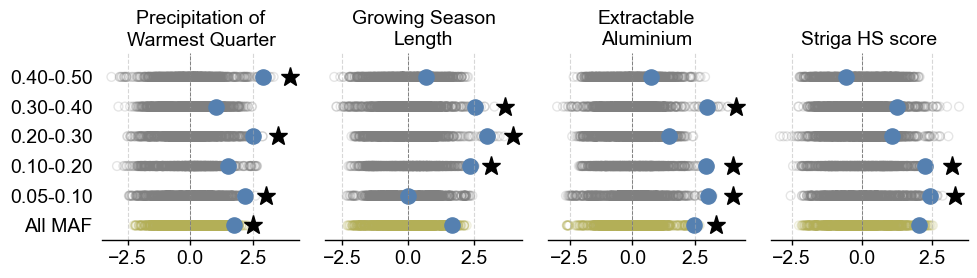

In [47]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

### 2.3 在CDS中的比较

#### 2.3.1 missense_vs_CDS

In [5]:
from src.enrich import contrast_runner

contrast_id = "missense_vs_CDS"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: missense_vs_CDS
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: `missense_cds_0.01`
  Background set: cds
  MAF stratify: ['all', 'maf_0.01_0.03_cds_0.01', 'maf_0.03_0.05_cds_0.01', 'maf_0.05_0.1_cds_0.01', 'maf_0.1_0.2_cds_0.01', 'maf_0.2_0.3_cds_0.01', 'maf_0.3_0.4_cds_0.01', 'maf_0.4_0.5_cds_0.01']
Permutations: 1000/1000 (100.0%) | elapsed 3.6s | 276.04/s | ETA 0.0s
1000 permutations with pool_num=40: 3.73 s (268.36 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.2s | 454.45/s | ETA 0.0s
1000 permutations with pool_num=40: 2.31 s (433.55 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.0s | 494.77/s | ETA 0.0s
1000 permutations with pool_num=40: 2.13 s (470.56 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.1s | 475.08/s | ETA 0.0s
1000 permutations with pool_num=40: 2.20 s (453.65 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.1s | 479.70/s | ETA 0.0s

Enrichment results for contrast: missense_vs_CDS


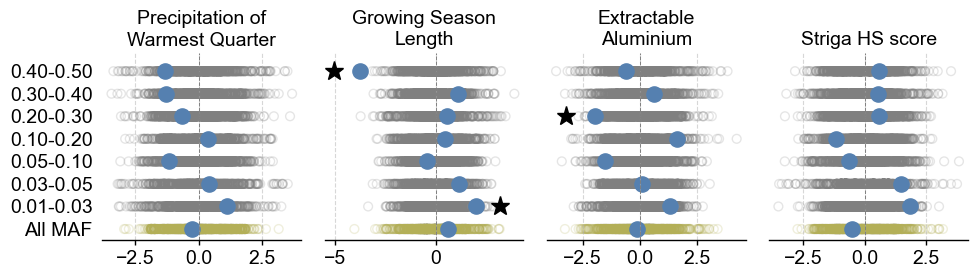

In [6]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.01_0.03_cds_0.01', '0.01-0.03'],
    ['maf_0.03_0.05_cds_0.01', '0.03-0.05'],
    ['maf_0.05_0.1_cds_0.01', '0.05-0.10'],
    ['maf_0.1_0.2_cds_0.01', '0.10-0.20'],
    ['maf_0.2_0.3_cds_0.01', '0.20-0.30'],
    ['maf_0.3_0.4_cds_0.01', '0.30-0.40'],
    ['maf_0.4_0.5_cds_0.01', '0.40-0.50']
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.3.2 synonymous_vs_CDS

In [7]:
from src.enrich import contrast_runner

contrast_id = "synonymous_vs_CDS"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: synonymous_vs_CDS
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: `synonymous_cds_0.01`
  Background set: cds
  MAF stratify: ['all', 'maf_0.01_0.03_cds_0.01', 'maf_0.03_0.05_cds_0.01', 'maf_0.05_0.1_cds_0.01', 'maf_0.1_0.2_cds_0.01', 'maf_0.2_0.3_cds_0.01', 'maf_0.3_0.4_cds_0.01', 'maf_0.4_0.5_cds_0.01']
Permutations: 1000/1000 (100.0%) | elapsed 3.9s | 258.79/s | ETA 0.0s
1000 permutations with pool_num=40: 3.99 s (250.62 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.6s | 384.50/s | ETA 0.0s
1000 permutations with pool_num=40: 2.71 s (369.43 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.4s | 409.62/s | ETA 0.0s
1000 permutations with pool_num=40: 2.55 s (391.72 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.4s | 416.89/s | ETA 0.0s
1000 permutations with pool_num=40: 2.50 s (400.18 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.6s | 385.84/s | ETA 

Enrichment results for contrast: synonymous_vs_CDS


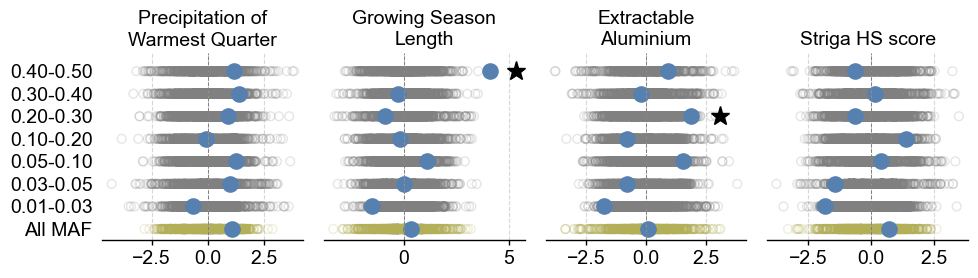

In [8]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.01_0.03_cds_0.01', '0.01-0.03'],
    ['maf_0.03_0.05_cds_0.01', '0.03-0.05'],
    ['maf_0.05_0.1_cds_0.01', '0.05-0.10'],
    ['maf_0.1_0.2_cds_0.01', '0.10-0.20'],
    ['maf_0.2_0.3_cds_0.01', '0.20-0.30'],
    ['maf_0.3_0.4_cds_0.01', '0.30-0.40'],
    ['maf_0.4_0.5_cds_0.01', '0.40-0.50']
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.3.3 putative_LoF_vs_CDS

In [9]:
from src.enrich import contrast_runner

contrast_id = "putative_LoF_vs_CDS"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: putative_LoF_vs_CDS
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: `putative_LoF_cds_0.01`
  Background set: cds
  MAF stratify: ['all', 'maf_0.01_0.03_cds_0.01', 'maf_0.03_0.05_cds_0.01', 'maf_0.05_0.1_cds_0.01', 'maf_0.1_0.2_cds_0.01', 'maf_0.2_0.3_cds_0.01', 'maf_0.3_0.4_cds_0.01', 'maf_0.4_0.5_cds_0.01']
Permutations: 1000/1000 (100.0%) | elapsed 3.8s | 259.95/s | ETA 0.0s
1000 permutations with pool_num=40: 3.98 s (251.33 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.4s | 424.15/s | ETA 0.0s
1000 permutations with pool_num=40: 2.45 s (407.47 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.1s | 471.69/s | ETA 0.0s
1000 permutations with pool_num=40: 2.21 s (452.74 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.4s | 411.18/s | ETA 0.0s
1000 permutations with pool_num=40: 2.54 s (393.82 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.4s | 422.55/s | 

Enrichment results for contrast: putative_LoF_vs_CDS


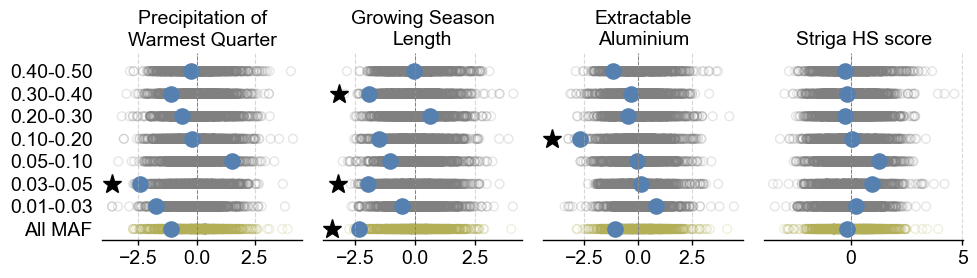

In [10]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.01_0.03_cds_0.01', '0.01-0.03'],
    ['maf_0.03_0.05_cds_0.01', '0.03-0.05'],
    ['maf_0.05_0.1_cds_0.01', '0.05-0.10'],
    ['maf_0.1_0.2_cds_0.01', '0.10-0.20'],
    ['maf_0.2_0.3_cds_0.01', '0.20-0.30'],
    ['maf_0.3_0.4_cds_0.01', '0.30-0.40'],
    ['maf_0.4_0.5_cds_0.01', '0.40-0.50']
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

#### 2.3.4 putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05

In [11]:
from src.enrich import contrast_runner

contrast_id = "putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
contrast['maf_stratify'] = ['all']
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: `putative_LoF_cds_0.01` & `maf_0.01_0.03_cds_0.01`
  Background set: `putative_LoF_cds_0.01` & `maf_0.03_0.05_cds_0.01`
  MAF stratify: ['all']
Permutations: 1000/1000 (100.0%) | elapsed 2.1s | 481.33/s | ETA 0.0s
1000 permutations with pool_num=40: 2.20 s (455.38 permutations/s)


Enrichment results for contrast: putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05


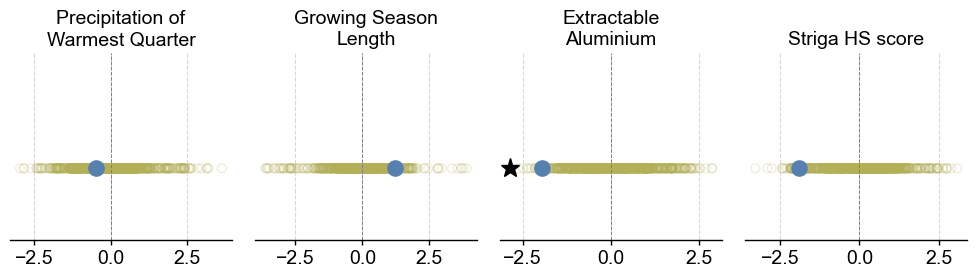

In [12]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', ''],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

## 3. Epigenomic features

### 3.1 ACR_vs_genome

In [48]:
from src.enrich import contrast_runner

contrast_id = "ACR_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: ACR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: ACR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 27.9s | 35.81/s | ETA 0.0s
1000 permutations with pool_num=40: 28.13 s (35.55 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 10.3s | 97.25/s | ETA 0.0s
1000 permutations with pool_num=40: 10.40 s (96.14 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.7s | 115.52/s | ETA 0.0s
1000 permutations with pool_num=40: 8.80 s (113.63 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.8s | 172.80/s | ETA 0.0s
1000 permutations with pool_num=40: 5.92 s (169.04 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.9s | 203.38/s | ETA 0.0s
1000 permutations with pool_num=40: 5.04 s (198.22 permutations/s)
Permutations: 1000/1000 (100.0%) | elapse

Enrichment results for contrast: ACR_vs_genome


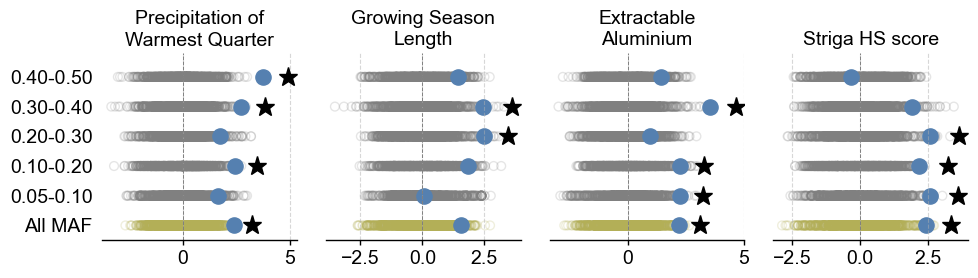

In [49]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

### 3.2 UMR_vs_genome

In [50]:
from src.enrich import contrast_runner

contrast_id = "UMR_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: UMR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: UMR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 27.7s | 36.05/s | ETA 0.0s
1000 permutations with pool_num=40: 27.99 s (35.73 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 10.1s | 99.23/s | ETA 0.0s
1000 permutations with pool_num=40: 10.19 s (98.12 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.0s | 110.74/s | ETA 0.0s
1000 permutations with pool_num=40: 9.16 s (109.14 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 6.1s | 163.97/s | ETA 0.0s
1000 permutations with pool_num=40: 6.23 s (160.54 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.3s | 188.01/s | ETA 0.0s
1000 permutations with pool_num=40: 5.43 s (184.29 permutations/s)
Permutations: 1000/1000 (100.0%) | elapse

Enrichment results for contrast: UMR_vs_genome


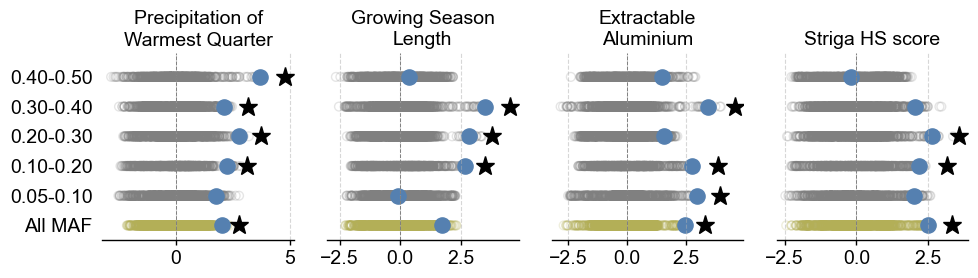

In [51]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

## 4. Genic proximal and distal

### 4.1 proximal_TE_vs_proximal

In [53]:
from src.enrich import contrast_runner

contrast_id = "proximal_TE_vs_proximal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: proximal_TE_vs_proximal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: genic_proximal & TE
  Background set: genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 14.1s | 70.78/s | ETA 0.0s
1000 permutations with pool_num=40: 14.34 s (69.75 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.5s | 180.20/s | ETA 0.0s
1000 permutations with pool_num=40: 5.69 s (175.68 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 6.1s | 163.88/s | ETA 0.0s
1000 permutations with pool_num=40: 6.24 s (160.14 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.4s | 228.82/s | ETA 0.0s
1000 permutations with pool_num=40: 4.49 s (222.74 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.0s | 251.31/s | ETA 0.0s
1000 permutations with pool_num=40: 4.08 s (244.86 permutations/s)
Permuta

Enrichment results for contrast: proximal_TE_vs_proximal


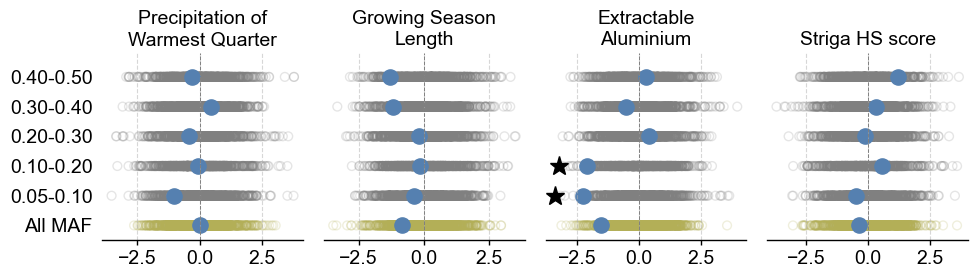

In [54]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

### 4.2 distal_TE_vs_distal

In [55]:
from src.enrich import contrast_runner

contrast_id = "distal_TE_vs_distal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: distal_TE_vs_distal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: (genome - genic_proximal) & TE
  Background set: genome - genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 17.5s | 56.98/s | ETA 0.0s
1000 permutations with pool_num=40: 17.76 s (56.31 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.4s | 134.73/s | ETA 0.0s
1000 permutations with pool_num=40: 7.53 s (132.80 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 6.6s | 150.48/s | ETA 0.0s
1000 permutations with pool_num=40: 6.76 s (148.00 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.8s | 264.65/s | ETA 0.0s
1000 permutations with pool_num=40: 3.90 s (256.67 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.6s | 276.87/s | ETA 0.0s
1000 permutations with pool_num=40: 3.73 s (268.05 permuta

Enrichment results for contrast: distal_TE_vs_distal


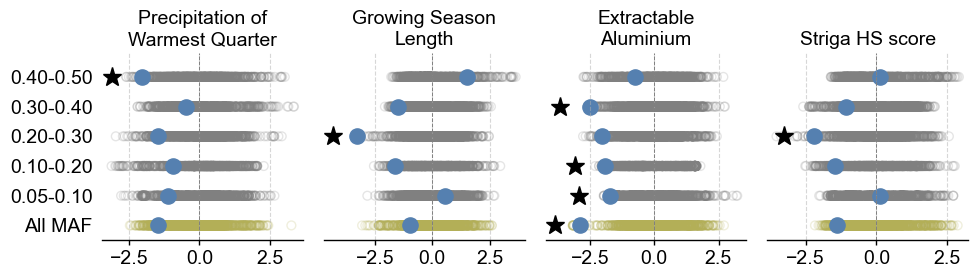

In [56]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

### 4.3 proximal_ACR_vs_proximal

In [57]:
from src.enrich import contrast_runner

contrast_id = "proximal_ACR_vs_proximal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: proximal_ACR_vs_proximal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: ACR & genic_proximal
  Background set: genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 15.5s | 64.68/s | ETA 0.0s
1000 permutations with pool_num=40: 15.68 s (63.79 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.8s | 208.88/s | ETA 0.0s
1000 permutations with pool_num=40: 4.91 s (203.69 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.5s | 182.25/s | ETA 0.0s
1000 permutations with pool_num=40: 5.62 s (178.01 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.9s | 254.34/s | ETA 0.0s
1000 permutations with pool_num=40: 4.07 s (245.65 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.9s | 259.26/s | ETA 0.0s
1000 permutations with pool_num=40: 3.97 s (252.02 permutations/s)
Permu

Enrichment results for contrast: proximal_ACR_vs_proximal


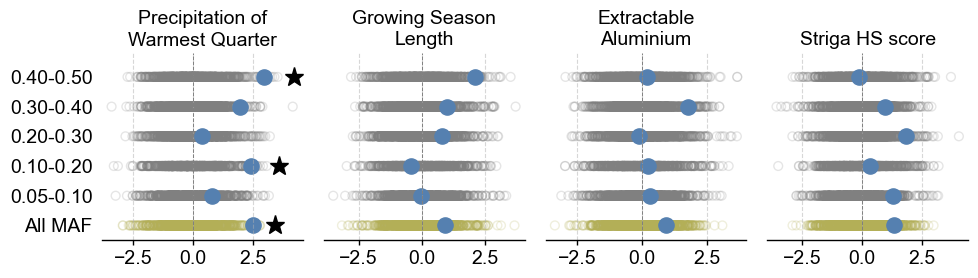

In [58]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

### 4.4 distal_ACR_vs_distal

In [59]:
from src.enrich import contrast_runner

contrast_id = "distal_ACR_vs_distal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: distal_ACR_vs_distal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: (genome - genic_proximal) & ACR
  Background set: genome - genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 14.7s | 68.16/s | ETA 0.0s
1000 permutations with pool_num=40: 14.84 s (67.39 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.3s | 136.96/s | ETA 0.0s
1000 permutations with pool_num=40: 7.45 s (134.29 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.6s | 177.07/s | ETA 0.0s
1000 permutations with pool_num=40: 5.78 s (172.93 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.7s | 271.00/s | ETA 0.0s
1000 permutations with pool_num=40: 3.84 s (260.74 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.5s | 287.36/s | ETA 0.0s
1000 permutations with pool_num=40: 3.61 s (276.67 permu

Enrichment results for contrast: distal_ACR_vs_distal


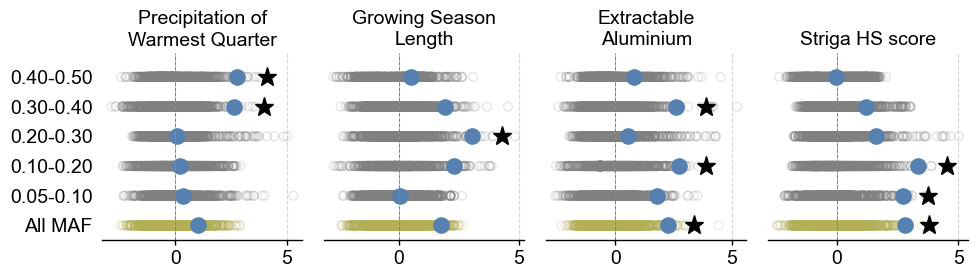

In [60]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

### 4.5 proximal_UMR_vs_proximal

In [61]:
from src.enrich import contrast_runner

contrast_id = "proximal_UMR_vs_proximal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: proximal_UMR_vs_proximal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: UMR & genic_proximal
  Background set: genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 13.6s | 73.79/s | ETA 0.0s
1000 permutations with pool_num=40: 13.71 s (72.91 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.5s | 222.18/s | ETA 0.0s
1000 permutations with pool_num=40: 4.63 s (215.92 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.3s | 187.70/s | ETA 0.0s
1000 permutations with pool_num=40: 5.46 s (183.19 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 4.1s | 246.14/s | ETA 0.0s
1000 permutations with pool_num=40: 4.18 s (239.07 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.8s | 264.20/s | ETA 0.0s
1000 permutations with pool_num=40: 3.93 s (254.53 permutations/s)
Permu

Enrichment results for contrast: proximal_UMR_vs_proximal


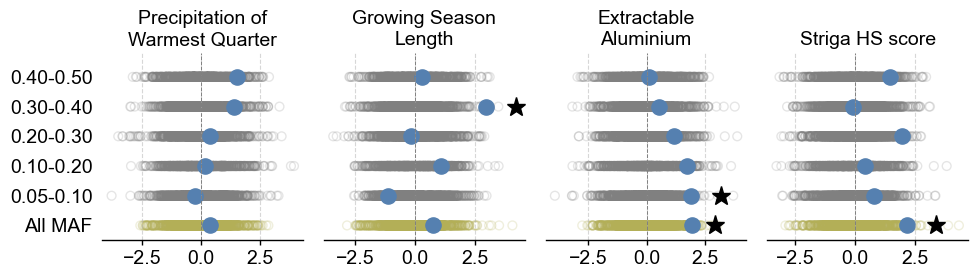

In [62]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

### 4.6 distal_UMR_vs_distal

In [63]:
from src.enrich import contrast_runner

contrast_id = "distal_UMR_vs_distal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: distal_UMR_vs_distal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: (genome - genic_proximal) & UMR
  Background set: genome - genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 13.7s | 73.25/s | ETA 0.0s
1000 permutations with pool_num=40: 13.81 s (72.39 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.5s | 181.50/s | ETA 0.0s
1000 permutations with pool_num=40: 5.67 s (176.51 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 5.9s | 170.28/s | ETA 0.0s
1000 permutations with pool_num=40: 6.02 s (166.12 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.6s | 278.99/s | ETA 0.0s
1000 permutations with pool_num=40: 3.71 s (269.63 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.6s | 280.82/s | ETA 0.0s
1000 permutations with pool_num=40: 3.70 s (270.55 permu

Enrichment results for contrast: distal_UMR_vs_distal


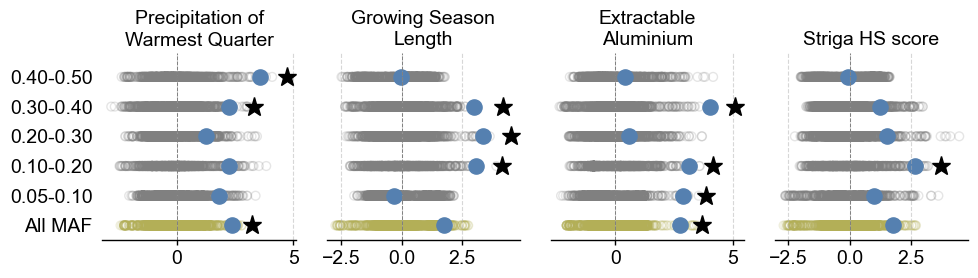

In [64]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)

### 4.7 proximal_ACR_not_TE_vs_proximal_TE_not_ACR

In [65]:
from src.enrich import contrast_runner

contrast_id = "proximal_ACR_not_TE_vs_proximal_TE_not_ACR"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: proximal_ACR_not_TE_vs_proximal_TE_not_ACR
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: (ACR & genic_proximal) - TE
  Background set: (TE & genic_proximal) - ACR
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 7.1s | 140.72/s | ETA 0.0s
1000 permutations with pool_num=40: 7.38 s (135.56 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.2s | 310.80/s | ETA 0.0s
1000 permutations with pool_num=40: 3.33 s (300.58 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.9s | 339.83/s | ETA 0.0s
1000 permutations with pool_num=40: 3.05 s (327.45 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 3.2s | 313.73/s | ETA 0.0s
1000 permutations with pool_num=40: 3.30 s (302.58 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 2.8s | 357.53/s | ETA 0.0s
1000 permutations with pool_num=40

Enrichment results for contrast: proximal_ACR_not_TE_vs_proximal_TE_not_ACR


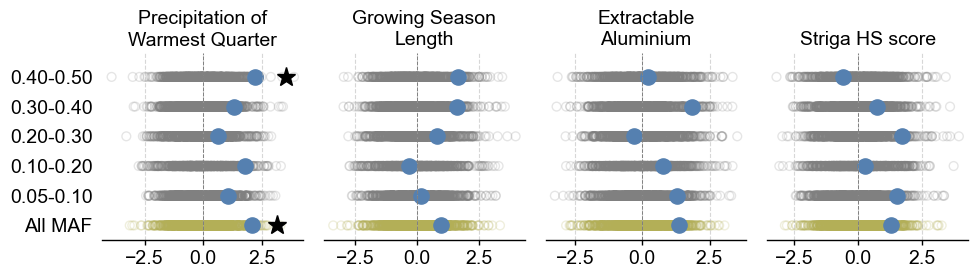

In [66]:
from src.enrich import plot_enrichment_results

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
plot_enrichment_results(results_json, env_id_list, env_metadata_df, stratify_label_map, significance_threshold=0.05)